# Genetic Risk Prediction: GWAS Polygenic Risk Scores (NBK 4)

This notebook focuses on predicting an individual's genetic risk for a trait using a **polygenic risk score (PRS)** built from **genome-wide association study (GWAS) summary statistics**. For each SNP, a GWAS provides an effect size (β) quantifying its association with some trait: say height, disease risk, cholesterol level, etc. A PRS combines these weighted SNP effects into a single genome-wide predictor for an individual.

We can apply the method to **1000 Genomes EUR individuals** using the **height GWAS** base data. To do this, we can use the standard **clumping + thresholding** pipeline, but now scoring across the entire genome from external summary statistics rather than from our own cis-eQTL regression. Finally, we can locate one 1000G individual within the resulting population distribution.

To begin, the following prerequisites are required to run this notebook without any errors:

- NBK 1 (`data_wrangling.ipynb`) reviewed, as this NBK uses the same `data/` layout.
- `data/genotype/LDREF/` populated with the 1000G EUR PLINK filesets (`1000G.EUR.{1..22}.{bed,bim,fam}`)
- `data/gwas/Height.gwas.txt.gz` (GWAS summary statistics base data)
- `tools/plink2` (or `plink2.exe`) in the `tools/` directory — required for LD clumping and scoring.
- Python environment with `numpy`, `pandas`, `scipy`, `matplotlib`, `bed-reader` installed (see `requirements.txt`)
- `helpers.py` present in the same directory as this notebook

---

### Import statements

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers

---

### Understanding GWAS-based PRS

A **Genome-Wide Association Study (GWAS)** tests every common SNP in the genome for statistical association with a trait or disease in a large cohort (say hundreds of thousands of people). The output is a **summary statistics** file: one row per SNP, reporting the estimated effect size β, standard error, p-value, allele frequency, etc.

A **polygenic risk score (PRS)** for one individual is:

$$\text{PRS}_i = \sum_{k \in \text{selected SNPs}} \beta_k \cdot \text{genotype}_{i,k}$$

where $\beta_k$ is the GWAS-reported effect size for SNP $k$ and $\text{genotype}_{i,k}$ is person $i$'s allele dosage at SNP $k$ (0 / 1 / 2). This is the same formula as an expression PRS with the only difference being the **source of β** (external GWAS summary stats vs. own cis-eQTL regression) and the **scale** (genome-wide vs. per-gene cis-window).

Before summing, we can apply the same **clumping + thresholding preprocessing**:

1. **Cleaning the GWAS file:** Converting the reported odds ratio (`OR`) into a log-scale effect size (`β`), dropping SNPs whose alleles can't be matched across datasets (A/T or C/G pairs, since flipping the DNA strand would hide which allele is which), removing low-quality or very rare SNPs, and getting rid of any duplicates. This leaves us with the "clean" summary statistics ready for scoring.
2. **Linkage disequilibrium clumping:** Nearby SNPs are often inherited together, so they're not independent pieces of information. For each chromosome, we can keep the strongest SNP in each correlated group and drop nearby SNPs using the 1000G EUR reference panel to figure out which SNPs are correlated.
3. **P-value thresholding:** Only including SNPs with p-values below some cutoff (stricter cutoffs give fewer but more trustworthy SNPs). We can try multiple cutoffs (say `0.001, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5`) since the best one isn't known beforehand.
4. **Score aggregation:** For each person, at each cutoff, adding up (SNP's effect × that person's dosage) across every surviving SNP on every chromosome. This will give us one PRS number per person per cutoff.


Since the 1000 Genomes individuals **have no measured phenotype** (no measured heights), we cannot pick the best threshold by regressing PRS against the true trait. As such, we can report the PRS distribution at each of the thresholds and locate an example individual within it.

---

### Loading the GWAS summary statistics

We can first load the **height GWAS summary statistics**: one row per SNP, reporting its estimated effect size (odds ratio) and association p-value with height, measured in the GWAS cohort. These are the raw weights that will become our PRS.

In [15]:
gwas_df = helpers.read_gwas_sumstats()
print(f"GWAS summary stats: {gwas_df.shape}")
print(f"Columns: {list(gwas_df.columns)}")
gwas_df.head()

GWAS summary stats: (529504, 11)
Columns: ['CHR', 'BP', 'SNP', 'A1', 'A2', 'N', 'SE', 'P', 'OR', 'INFO', 'MAF']


,CHR,BP,SNP,A1,A2,N,SE,P,OR,INFO,MAF
0,1,756604,rs3131962,A,G,388028,0.003017,0.483171,0.997887,0.890558,0.369390
1,1,768448,rs12562034,A,G,388028,0.003295,0.834808,1.000687,0.895894,0.336846
2,1,779322,rs4040617,G,A,388028,0.003033,0.428970,0.997604,0.897508,0.377368
3,1,801536,rs79373928,G,T,388028,0.008413,0.808999,1.002036,0.908963,0.483212
4,1,808631,rs11240779,G,A,388028,0.002428,0.590265,1.001308,0.893213,0.450410


The file contains ~530K SNPs. Key columns are `SNP` (rsID), `A1` (effect allele), `A2` (other allele), `OR` (odds ratio, the effect size we can convert to a log-scale β), `INFO` (imputation quality), `MAF` (minor allele frequency), and `P` (association p-value).

---

### Quality-controlling the summary statistics

Raw GWAS output needs to be quality controlled before being used in a PRS. We can apply the preprocessing defined in `helpers.qc_sumstats`, which:

1. **Converts OR → BETA** via `β = log(OR)`, the natural effect-size scale for linear aggregation
2. **Removes strand-ambiguous SNPs** (A/T and C/G pairs) as their allele can't be matched across datasets without strand information
3. **Filters by imputation quality** (`INFO > 0.8`) as low-quality imputations introduce noise
4. **Filters by minor allele frequency** (`MAF > 0.01`) as rare variants have unreliable effect estimates
5. **Deduplicates** on SNP ID

The quality controlled summary statistics are also written to `Height.QC.txt` so plink can use them for clumping and scoring.

In [16]:
output_dir = Path("../output/gwas_prs")
output_dir.mkdir(parents=True, exist_ok=True)

qc_df = helpers.qc_sumstats(gwas_df)
score_file = output_dir / "Height.QC.txt"
qc_df.to_csv(score_file, sep="\t", index=False)

print(f"Before quality control: {len(gwas_df):,} SNPs")
print(f"After  quality control: {len(qc_df):,} SNPs")
print(f"Saved quality controlled summary statistics to {score_file}.")

Before quality control: 529,504 SNPs
After  quality control: 499,617 SNPs
Saved quality controlled summary statistics to ..\output\gwas_prs\Height.QC.txt.


About 30,000 SNPs were dropped by quality control. The remaining ~500,000 are high-quality, strand-unambiguous, common variants. We can use these to build our PRS.

---

### Preparing plink input files

Plink's PRS scoring step requires two supporting files besides the summary statistics:

- **`SNP.pvalue`**: a 2-column (SNP, P) file plink uses to assign each SNP to a p-value threshold bucket
- **`range_list`**: 1 line per threshold defining the range for scoring. Here we use: `0.001, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5`. The labels on the first column become the filename suffix of each output score file (e.g., `.0.001.sscore`).

In [17]:
qc_df[["SNP", "P"]].to_csv(output_dir / "SNP.pvalue", sep="\t", header=False, index=False)
helpers.write_range_list(output_dir / "range_list")
print(f"Writing SNP.pvalue and range_list to {output_dir}.")
print("\nrange_list content:")
print((output_dir / "range_list").read_text())

Writing SNP.pvalue and range_list to ..\output\gwas_prs.

range_list content:
0.001 0 0.001
0.05 0 0.05
0.1 0 0.1
0.2 0 0.2
0.3 0 0.3
0.4 0 0.4
0.5 0 0.5



---

### Linkage disequilibrium clumping per chromosome

Before scoring, we can **LD-clump** the summary statistics against the 1000G EUR reference panel, one chromosome at a time, using the same clumping parameters (`r² < 0.1`, 250 kb window). The helper `helpers.clump_per_chromosome` runs plink `--clump` on each chromosome and collects the **index SNPs** (statistically independent lead SNPs) from each chromosome's `.clumps` file. These index SNPs define the PRS scoring set.

In [18]:
index_snps = helpers.clump_per_chromosome(score_file, output_dir, prefix="clump")
valid_snp_file = output_dir / "EUR.valid.snp"
valid_snp_file.write_text("\n".join(index_snps) + "\n")

print(f"Total index SNPs after clumping: {len(index_snps):,}")
print(f"Written to {valid_snp_file}.")

Total index SNPs after clumping: 67,388
Written to ..\output\gwas_prs\EUR.valid.snp.


About ~67,000 SNPs survive clumping across all 22 chromosomes. This is approximately a ~7× reduction from the quality controlled 500,000. These remaining SNPs represent independent signals where each one contributes a unique piece of information to the final PRS rather than echoing its neighbors.

---

### Scoring all 489 individuals at 7 thresholds

For each chromosome, we can now call `plink2 --score ... --q-score-range ...` which computes PRS at **all seven p-value thresholds in a single pass**. The per-chromosome score files are then aggregated across chromosomes to produce one genome-wide PRS per individual per threshold.

In [19]:
for chrom in range(1, 23):
    bfile = helpers.ldref_prefix(chrom)
    if not Path(f"{bfile}.bed").exists():
        continue
    helpers.plink_score(
        bfile, score_file, output_dir / f"score_chr{chrom}",
        snp_col=list(qc_df.columns).index("SNP") + 1,
        a1_col=list(qc_df.columns).index("A1") + 1,
        beta_col=list(qc_df.columns).index("BETA") + 1,
        q_range=output_dir / "range_list",
        q_values=output_dir / "SNP.pvalue",
        extract=valid_snp_file,
    )

THRESHOLDS = [0.001, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
kg_scores = {t: helpers.aggregate_scores(output_dir, "score", str(t)) for t in THRESHOLDS}
print(f"Scored {len(kg_scores[THRESHOLDS[0]])} individuals at {len(THRESHOLDS)} thresholds.")

Scored 489 individuals at 7 thresholds.


All 489 1000G EUR individuals now have a PRS computed at each of the seven thresholds. Each threshold produces a different distribution: stricter thresholds (p ≤ 0.001) use fewer but more-confident SNPs, whereas permissive thresholds (p ≤ 0.5) use far more SNPs including noisier ones.

---

### PRS distribution summary across thresholds

Here we look at the distributional shape of the 489-person PRS at each threshold: specifically the mean and standard deviation. These tell us how "spread out" people are at each threshold, as a broader distribution means individual-level PRS comparisons are more discriminating.

In [20]:
summary = pd.DataFrame([{"threshold": t, "n": len(kg_scores[t]), "mean": kg_scores[t]["prs"].mean(), "sd": kg_scores[t]["prs"].std()} for t in THRESHOLDS])
summary

,threshold,n,mean,sd
0,0.001,489,0.899573,0.872040
1,0.050,489,-0.064572,1.092277
2,0.100,489,-0.102536,1.120246
3,0.200,489,-0.042491,1.151029
4,0.300,489,0.086548,1.165091
5,0.400,489,-0.028404,1.166135
6,0.500,489,0.035423,1.166872


---

### Locating an example individual in the distribution

Since the 1000G individuals **have no measured height**, we cannot pick a "best threshold" by regressing PRS against the true trait. Instead, we can pick **one 1000G individual** and report where they sit in the population distribution at each threshold. We can use `HG00096`, the first individual alphabetically, as a deterministic choice.


In [21]:
example_iid = sorted(kg_scores[THRESHOLDS[0]]["IID"])[0]
print(f"Example individual: {example_iid}")

def individual_prs(t):
    row = kg_scores[t].loc[kg_scores[t]["IID"] == example_iid, "prs"]
    return float(row.iloc[0]) if len(row) else np.nan

individual = {t: individual_prs(t) for t in THRESHOLDS}
summary["individual_prs"] = [individual[t] for t in THRESHOLDS]
summary["percentile"] = [round(float(np.mean(kg_scores[t]["prs"] < individual[t]) * 100), 1) for t in THRESHOLDS]
summary

Example individual: HG00096


,threshold,n,mean,sd,individual_prs,percentile
0,0.001,489,0.899573,0.872040,-1.052997,1.6
1,0.050,489,-0.064572,1.092277,-2.747409,0.8
2,0.100,489,-0.102536,1.120246,-2.953341,0.8
3,0.200,489,-0.042491,1.151029,-2.824995,1.4
4,0.300,489,0.086548,1.165091,-2.587001,1.4
5,0.400,489,-0.028404,1.166135,-2.584420,1.6
6,0.500,489,0.035423,1.166872,-2.601988,1.2


At each threshold, we can now report the individual's **absolute PRS value** and their **percentile** within the 489-person 1000G EUR distribution.

---

### Visualising the PRS distribution

Plotting a histogram of the 1000G PRS distribution at the strictest threshold (`p ≤ 0.001`), with the example individual marked.

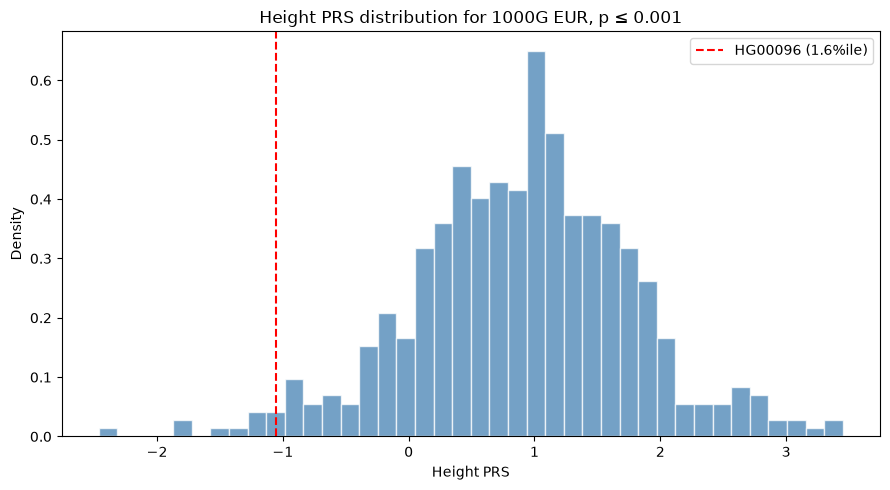

In [22]:
t0 = 0.001
vals = kg_scores[t0]["prs"].to_numpy()
pct = np.mean(vals < individual[t0]) * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(vals, bins=40, density=True, color="steelblue", alpha=0.75, edgecolor="white")
ax.axvline(individual[t0], color="red", ls="--", lw=1.5,
           label=f"{example_iid} ({pct:.1f}%ile)")
ax.legend()
ax.set(xlabel="Height PRS", ylabel="Density",
       title=f"Height PRS distribution for 1000G EUR, p ≤ {t0}")
fig.tight_layout()
plt.show()

The distribution is approximately bell-shaped, as expected for a sum of many small SNP effects. The example individual's position is indicated by the dashed red line.


---